# Clustering WPT packets using fuzzy c-means

In [48]:
import sys

if sys.version_info[0] + 0.1 * sys.version_info[1] < 3.6:
    raise Exception("Must be using Python 3.6+ version")

In [49]:
%matplotlib inline
sys.path.append("..")
from wavelet_transform.wpt import transform as wpt
# from wavelet_transform.test import synthetic_data as sd
from wavelet_transform.wpt import inverse_transform as inv
from wavelet_transform.postprocess import plotting as plot
import wavelet_transform.utils.statistical_features as stats
from wavelet_transform.utils.bubbledynamics import BubbleDynamics as BD

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [50]:
pac = -5E5                     # the amplitude of the sine wave in Pa
frequency = 5*1E5             # insonation frequency (Hz)
no_cycle = 20                   # no. of cycles of the sine wave
sampling_rate = frequency*20              # sampling rate to generate the time vector
tstep = 1./sampling_rate
tmax = no_cycle/frequency 
time = np.arange(0.,tmax,tstep) # time vector for computing the sine wave, in seconds
t_plot = time

R_init = 10E-6                  # initial bubble radius in meters
Rdot_init = 0                   # initial bubble's wall velocity in m/s

r_measure = 50*R_init           # distance from the centre of bubble which radiated pressure (acoustic emission from bubble) is calculated over time 

std_noise = 0.01

wavelet = "db10"
levels = 7
mode = "symmetric"

fft_lim = 10*frequency  # increase value to view more of the fft plots

### Generating acoustic emission data using Gilmore-Akulichev model

In [51]:
# generate sound wave

BD_obj = BD(R_init,Rdot_init,frequency,pac,time,tstep)
BD_obj.solver()
BD_obj.calculate_p_radiated(r_measure = r_measure)

data = BD_obj.p_radiated
time = BD_obj.time

signal_length = len(data)

# data += sd.noise(std_noise, duration=time[-1]+tstep, sampling_rate=sampling_rate)

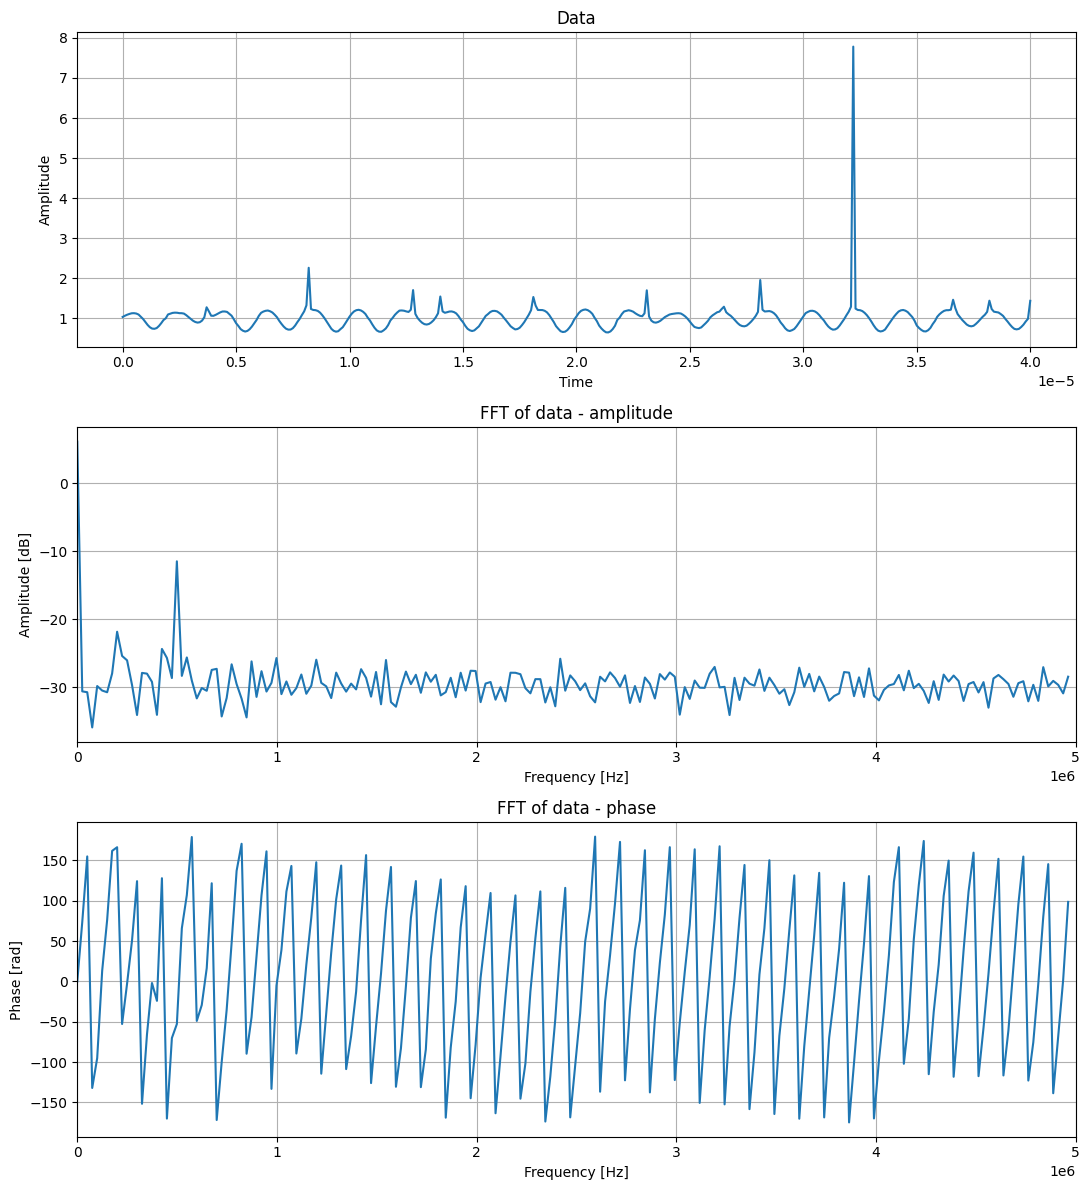

In [52]:
fft_data = np.fft.fft(data)[0 : int(signal_length / 2)] / (
    signal_length / 2
)  # division by signal_length/2 is to correct the amplitude (energy) in the freq domain
freq = np.fft.fftfreq(signal_length, d=1 / sampling_rate)[0 : int(signal_length / 2)]

# plot sound wave and fft
fig, ax = plt.subplots(3, figsize=(11, 12))
ax[0].plot(t_plot, data)
ax[0].set_title("Data")
ax[0].set_xlabel("Time")
ax[0].set_ylabel("Amplitude")
ax[0].grid()

ax[1].plot(
    freq,
    20*np.log10(np.abs(fft_data))
)
ax[1].set_title("FFT of data - amplitude")
ax[1].set_xlabel("Frequency [Hz]")
ax[1].set_ylabel("Amplitude [dB]")
ax[1].set_xlim(0, fft_lim)
ax[1].grid()

ax[2].plot(freq, np.angle(fft_data, deg=True))
ax[2].set_title("FFT of data - phase")
ax[2].set_xlabel("Frequency [Hz]")
ax[2].set_ylabel("Phase [rad]")
ax[2].set_xlim(0, fft_lim)
ax[2].grid()
fig.tight_layout()
plt.show()

In [53]:
# Set display options
pd.set_option("display.max_rows", None)  # Show all rows
pd.set_option("display.max_columns", None)  # Show all columns


# DWPT
tr_ob = wpt.dwpt(data, levels, wavelet, mode)
tr_ob.calc_frequencies(sampling_rate)

# calculate energy, kurtosis, and crest factor of reconstructed signals
wpt_df = pd.DataFrame(
    columns=[
        "node",
        "inverse",
        "fft",
        "energy",
        "kurtosis",
        "crest",
        "entropy",
        "skewness",
    ]
)

total_energy = stats.calc_energy(data)

# reconstruct each node separately
counter = 0
for node in tr_ob.get_level(level=levels, order="freq"):
    node_data = node.data  # coefficients from transform

    # calculate inverse transform
    inverse = inv.inv_dwpt(tr_ob)
    inverse_signal_length = len(inverse)

    # calculate fft of inverse
    fft = np.fft.fft(inverse)[0 : int(inverse_signal_length / 2)] / (
        inverse_signal_length * 0.5
    )

    # calculate statistical measures
    entropy_node = stats.calc_entropy(node.energy, total_energy)
    kurtosis = stats.calc_kurtosis(node_data)
    skewness = stats.calc_skewness(node_data)
    crest = stats.calc_crest_factor(node_data)

    wpt_df.loc[counter, "node"] = node
    wpt_df.loc[counter, "inverse"] = inverse
    wpt_df.loc[counter, "fft"] = fft
    wpt_df.loc[counter, "energy"] = node.energy
    wpt_df.loc[counter, "kurtosis"] = kurtosis
    wpt_df.loc[counter, "crest"] = crest
    wpt_df.loc[counter, "entropy"] = entropy_node
    wpt_df.loc[counter, "skewness"] = skewness
    counter += 1

tr_ob.info(level=levels, order="freq").head()

,node number,energy,kurtosis,crest factor,skewness,frequency range
0,0,0.261315,7.207793,-5.483471,2.375385,"(0.0, 3.906e4)"
1,1,0.073296,4.332919,1.676811,0.154644,"(3.906e4, 7.812e4)"
2,3,0.130146,3.778408,1.743616,0.761232,"(7.812e4, 1.172e5)"
3,2,0.048489,2.808293,0.692153,-0.108706,"(1.172e5, 1.562e5)"
4,6,0.175678,2.953755,0.078973,0.280838,"(1.562e5, 1.953e5)"


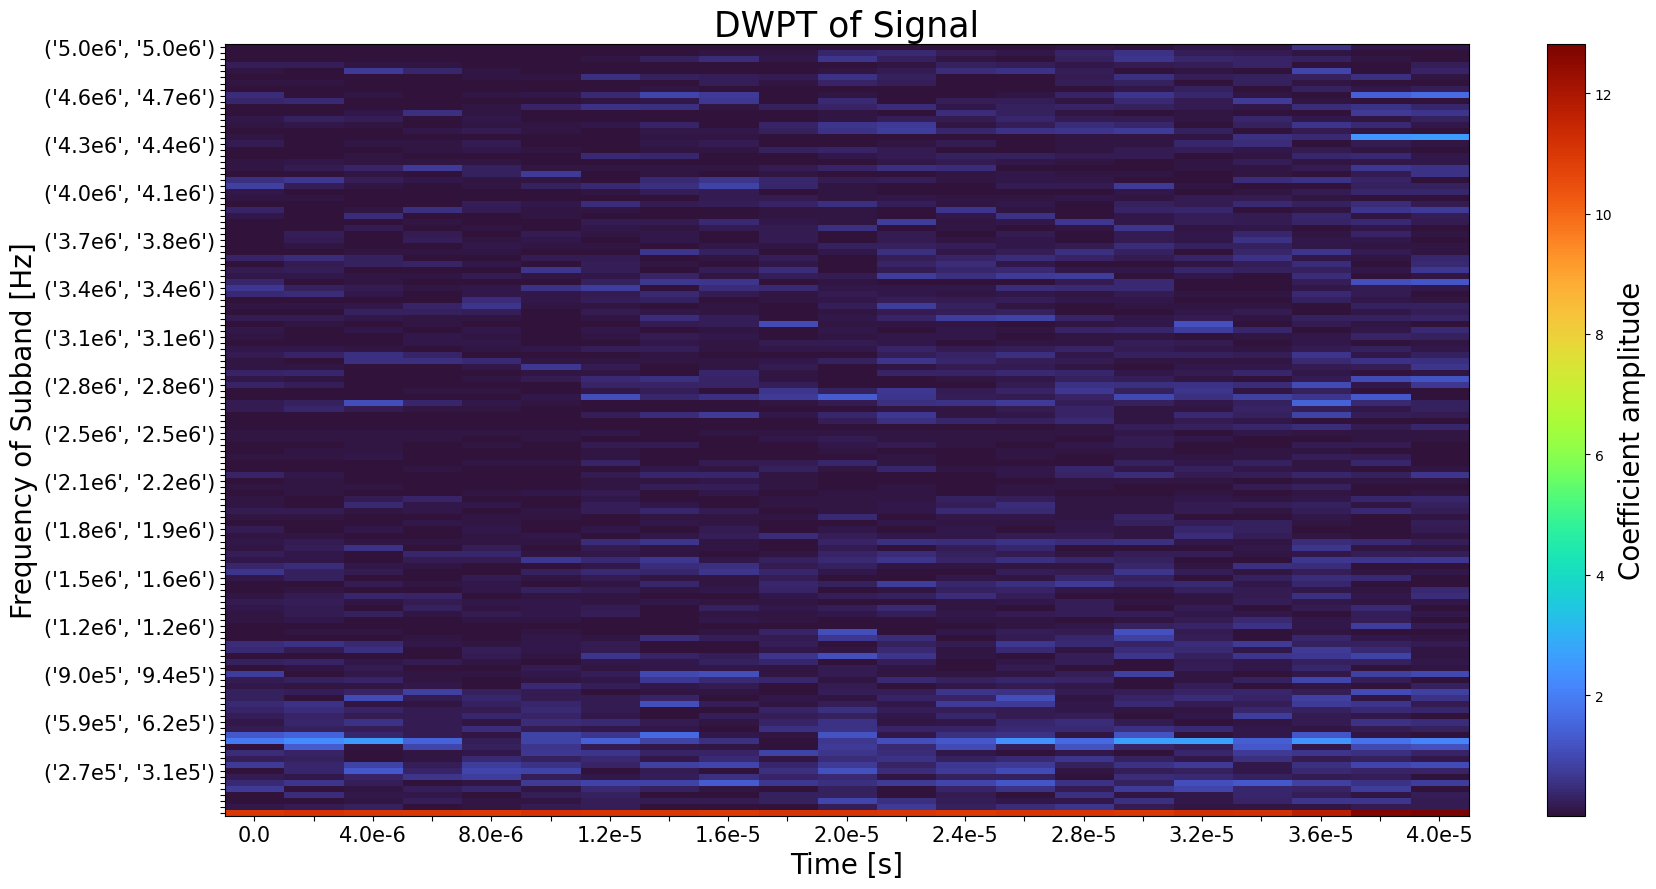

In [54]:
plot.heisenberg(tr_ob, max(t_plot))

## Fuzzy c-means clustering

In [55]:
from sklearn.preprocessing import StandardScaler
import skfuzzy as fuzz

# get data
classifying_metrics = ["entropy", "kurtosis", "crest"]
data_train = wpt_df[classifying_metrics]

# standardise data
scaler = StandardScaler()
data_train_normalised = scaler.fit_transform(data_train)

# parameters for Fuzzy C-means
no_clusters = 3
m = 2.0
error = 1e-6

# Fuzzy C-Means clustering
cntr, u, u0, d, jm, p, fpc = fuzz.cluster.cmeans(
    data_train_normalised.T,
    c=no_clusters,
    m=m,
    error=error,
    maxiter=100,
)
print("number of iterations:", p)
# cluster centres
centers = scaler.inverse_transform(cntr.T)

# membership matrix
membership_matrix = u.T

# hard cluster assignments
labels = np.argmax(membership_matrix, axis=1)

membership_results = pd.DataFrame()
for i, membership in enumerate(membership_matrix):
    membership_results.loc[i, "hard assignment"] = labels[i]
    for j in range(no_clusters):
        membership_results.loc[i, f"membership {j}"] = membership[j]

membership_results.head()

number of iterations: 99


,hard assignment,membership 0,membership 1,membership 2
0,0.0,0.424393,0.325858,0.249749
1,1.0,0.077196,0.807325,0.115478
2,1.0,0.048908,0.904984,0.046107
3,1.0,0.192975,0.779713,0.027311
4,0.0,0.499642,0.471131,0.029227


In [56]:
from sklearn import metrics
from collections import defaultdict
from time import time
evaluations = []
evaluations_std = []

def fit_and_evaluate(X, labels, n_runs=50):
    name = "fuzzy c-means"

    train_times = []
    scores = defaultdict(list)
    for _ in range(n_runs):
        t0 = time()

        _, u, *_ = fuzz.cluster.cmeans(X, c=no_clusters, m=m, error=error, maxiter=150)
        membership_matrix = u.T
        new_labels = np.argmax(membership_matrix, axis=1)

        train_times.append(time() - t0)
        scores["Homogeneity"].append(metrics.homogeneity_score(labels, new_labels))
        scores["Completeness"].append(metrics.completeness_score(labels, new_labels))
        scores["V-measure"].append(metrics.v_measure_score(labels, new_labels))
        scores["Adjusted Rand-Index"].append(
            metrics.adjusted_rand_score(labels, new_labels)
        )
        scores["Silhouette Coefficient"].append(
            metrics.silhouette_score(X.T, new_labels, sample_size=2000)
        )
    train_times = np.asarray(train_times)

    print(f"clustering done in {train_times.mean():.2f} ± {train_times.std():.2f} s ")
    evaluation = {
        "estimator": name,
        "train_time": train_times.mean(),
    }
    evaluation_std = {
        "estimator": name,
        "train_time": train_times.std(),
    }
    for score_name, score_values in scores.items():
        mean_score, std_score = np.mean(score_values), np.std(score_values)
        print(f"{score_name}: {mean_score:.3f} ± {std_score:.3f}")
        evaluation[score_name] = mean_score
        evaluation_std[score_name] = std_score
    evaluations.append(evaluation)
    evaluations_std.append(evaluation_std)

In [57]:
fit_and_evaluate(data_train_normalised.T, labels)

clustering done in 0.01 ± 0.00 s 
Homogeneity: 0.954 ± 0.017
Completeness: 0.965 ± 0.012
V-measure: 0.960 ± 0.015
Adjusted Rand-Index: 0.975 ± 0.013
Silhouette Coefficient: 0.387 ± 0.003


Post hoc assignment of cluster labels. Highest cluster number is the lowest entropy cluster, the rest is sorted by kurtosis or crest factor.

In [62]:
def map_labels_entropy(centers, labels, sort_by=1):
    """
    assign labels to clusters. Assign the highest cluster number to the centre with
    lowest entropy. Then assign the rest in order of sort_by. The group numbers are reassigned
    to 1-indexed groups.

    Paramaters
    -----------
    centers: array
        array where each row is a centre of a cluster
    labels: list
        list of group assignments to reassign
    sort_by: int
        always sort out the highest energy because the harmonic can be separated
        from the rest by its much greater energy. Otherwise, sort by attribute
        number = sort_by of the centres. e.g. sort_by == 1 will sort the rest
        by kurtosis, sort_by == 2 will sort by crest factor etc.
    """
    # sort labels by entropy, lowest entropy is highest group number
    sort_by_entropy = np.argsort(centers[:, 0])[::-1]  # assumes entropy is in 1st position

    # sort rest of the labels by kurtosis
    sort_rest = np.argsort(centers[:, sort_by])

    sort_rest = np.delete(
        sort_rest,  # delete lowest entropy group form kurtosis
        np.where(sort_rest == sort_by_entropy[-1])[0][0],
        axis=0,
    )
    sort_rest = np.append(sort_rest, None)

    # create mapping from old cluster labels to new cluster labels
    mapping = {}
    for new_label, index in enumerate(zip(sort_by_entropy, sort_rest)):
        if new_label == len(sort_by_entropy) - 1:  # highest group no has highest energy
            mapping[index[0]] = new_label + 1
        else:
            mapping[index[1]] = (
                new_label + 1
            )  # other group numbers are arranged by kurtosis

    return mapping

In [64]:
mapping = map_labels_entropy(centers, labels)
print(mapping)

{1: 1, 0: 2, 2: 3}


In [71]:
# reassigning labels
reassigned_labels = [mapping[label] for label in labels]
print(reassigned_labels)

[2, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 2, 1, 3, 3, 3, 2, 2, 2, 2, 2, 1, 1, 2, 2, 2, 2, 3, 2, 1, 1, 1, 3, 2, 1, 1, 1, 1, 2, 1, 1, 1, 1, 2, 2, 2, 2, 1, 3, 1, 1, 3, 2, 1, 1, 3, 2, 3, 2, 1, 2, 2, 1, 3, 3, 1, 2, 1, 1, 1, 2, 3, 1, 1, 2, 2, 1, 1, 3, 1, 3, 1, 1, 1, 2, 2, 1, 1, 2, 3, 1, 1, 2, 1, 1, 3, 1, 1, 2, 3, 2, 1, 3, 1, 1, 2, 3, 2, 1, 1, 3]


### Calculating soft assignment

Reassign labels by taking summing the cluster numbers each data point belongs to, weigted by their membership to the cluster. Result is a membership number [1, 3]. 2-3 indicates mixture between harmonic (3) and transient (2). values between 1-2 are more transient when approaching 2. The hard assignment can be found as reassigned_labels above.

In [68]:
soft_assignments = [
    sum([mapping[i] * weight for i, weight in enumerate(membership)])
    for membership in membership_matrix
]
print(soft_assignments)

[1.923890404229269, 1.3081528194094127, 1.1411225748901774, 1.2475980751856308, 1.5580959692142218, 1.8580474703585723, 1.5655873261516635, 1.8092686184929991, 1.8882950062288157, 1.9516247804062405, 1.9740194267159334, 1.8907534131604435, 1.9732795057556054, 1.7394583909453785, 1.9462840404240955, 1.933650819891949, 1.47341465673474, 1.9556764083025038, 1.1927408487076967, 1.0923182943598928, 1.061357551464995, 1.2369368439572295, 1.1771793531608337, 1.4826292740243316, 1.1388710516088716, 1.9546275542545326, 1.45613423437539, 1.3173697518552816, 1.9194543171888192, 1.2575223390030466, 2.6842471946161526, 2.9066791087158492, 2.562903176509951, 1.9193646450505863, 1.6824333029672205, 1.9602343122268737, 1.6529698218795155, 1.786608622966865, 1.153491288413694, 1.3372940294262003, 1.894759999299911, 1.9823775976412061, 1.906236869692074, 1.8067046863026983, 2.1862990450217215, 1.9585146632174062, 1.1889007235808722, 1.3991188402615315, 1.1787987427693776, 2.961412932399544, 1.9846071700

Plot results

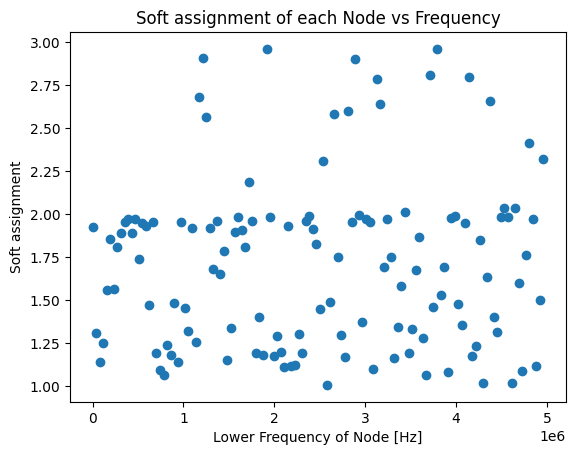

In [69]:
# plot weighted reassigned labels
plt.scatter([node.frequency_range[0] for node in wpt_df["node"]], soft_assignments)
plt.title("Soft assignment of each Node vs Frequency")
plt.xlabel("Lower Frequency of Node [Hz]")
plt.ylabel("Soft assignment")
plt.show()

C:\Users\maxau\AppData\Local\Temp\ipykernel_23680\2439160435.py:7: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap("Set1")


TypeError: inverse_transform() missing 1 required positional argument: 'X'

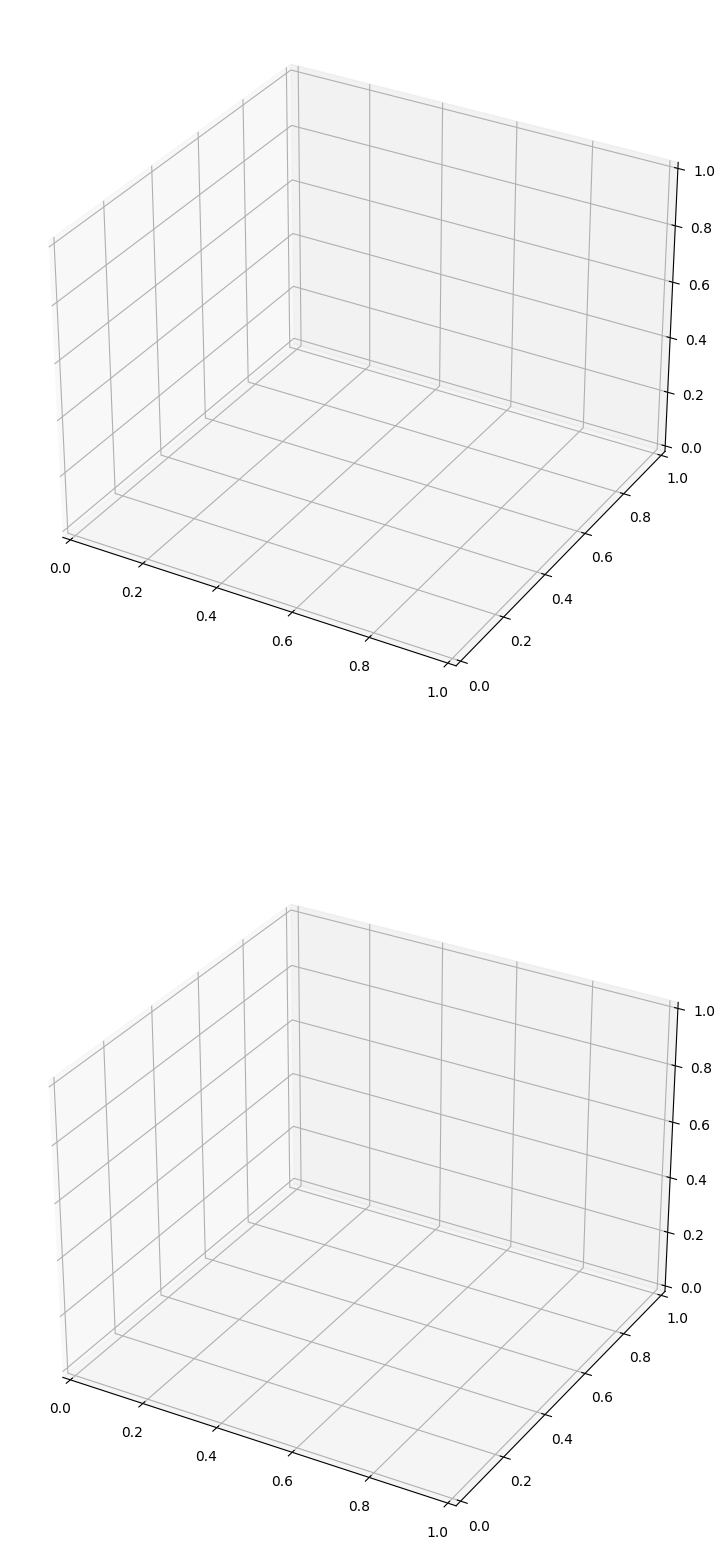

In [74]:
fig, ax = plt.subplots(2, figsize=(20, 20), subplot_kw={"projection": "3d"})

title = "Original Data"

# plot subplots for PCA data and non-PCA data
for i, ax in enumerate(ax):
    cmap = plt.cm.get_cmap("Set1")
    if i == 0:
        data_scatter = data_train.values.tolist()
        centers_scatter = StandardScaler.inverse_transform(centers)
        labels_scatter = reassigned_labels
        color_map_labels = reassigned_labels

    ax.scatter(
        [point[0] for point in data_scatter],
        [point[1] for point in data_scatter],
        [point[2] for point in data_scatter],
        # c=[cmap(label) for label in labels_scatter],
        c=color_map_labels
    )
    ax.scatter(
        centers_scatter[:, 0],
        centers_scatter[:, 1],
        centers_scatter[:, 2],
        c="red",
        marker="x",
        s=100,
    )

    ax.set_xlabel(data_train.columns[0])
    ax.set_ylabel(data_train.columns[1])
    ax.set_zlabel(data_train.columns[2])
    ax.set_title(title)

plt.show()